# **This is BeanGuard, a project that detects disease in Bean Leaves, built by Wazingwa Mugala**

In [1]:
!pip -q install datasets gradio

In [2]:
import json, random
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import models, transforms
from datasets import  load_dataset
torch.manual_seed(42) ; random.seed(42); np.random.seed(42)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Hey, you are using: ", device) # this should print cuda

Hey, you are using:  cpu


In [3]:
ds = load_dataset("AI-Lab-Makerere/beans")
print(ds)
labels = ds["train"].features["labels"].names
print("Classes:", labels)
print("Train counts:", Counter(ds["train"]["labels"]))
json.dump(labels, open("labels.json", "w"))

README.md:   0%|          | 0.00/4.95k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  144MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 18.5MB            

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 17.7MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/1034 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/133 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/128 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['image_file_path', 'image', 'labels'],
        num_rows: 1034
    })
    validation: Dataset({
        features: ['image_file_path', 'image', 'labels'],
        num_rows: 133
    })
    test: Dataset({
        features: ['image_file_path', 'image', 'labels'],
        num_rows: 128
    })
})
Classes: ['angular_leaf_spot', 'bean_rust', 'healthy']
Train counts: Counter({1: 348, 0: 345, 2: 341})


Image Size: (500, 500)


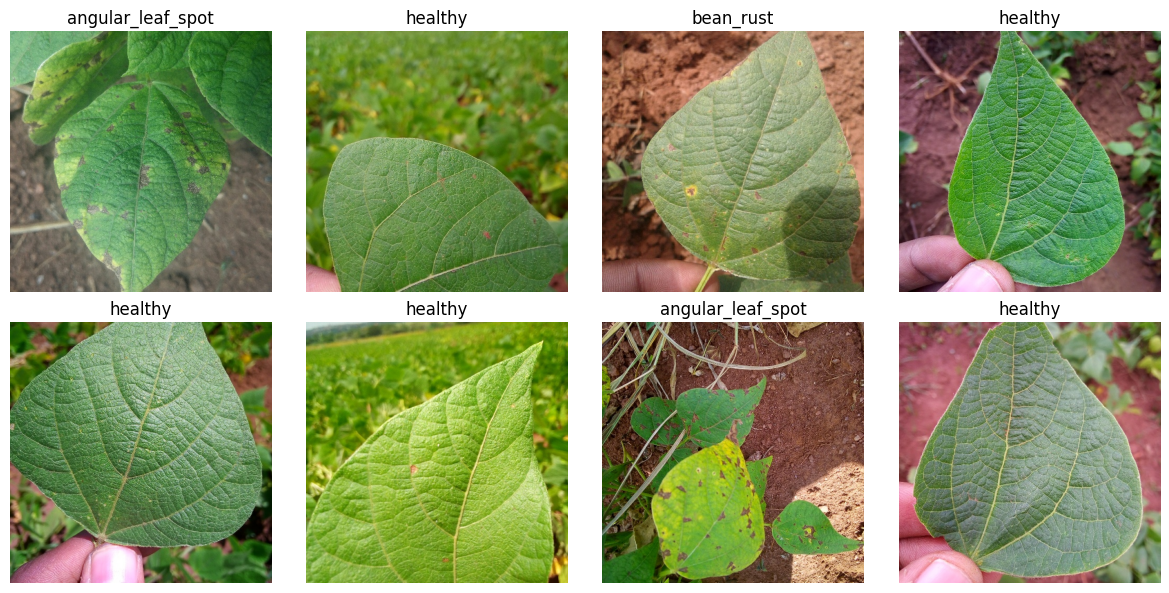

In [4]:
# Looking at my data before modelling.
sample = ds ["train"].shuffle(seed=0).select(range(8))
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax, ex in zip(axes.flat, sample) :
  ax.imshow(ex["image"])
  ax.set_title(labels[ex["labels"]])
  ax.axis("off")
plt.tight_layout()
print("Image Size:" , sample[0]["image"].size)

Preparing the Data - Transform (Resize, Auguemt, normalise)

In [5]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

train_tf = transforms.Compose([
    transforms.RandomResizedCrop(224, scale = (0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(0.2,0.2,0.2, 0.2),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])
eval_tf = transforms.Compose ([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])
def make_transfrom (tf) :
  def apply (batch):
    batch['pixel_values'] = [tf(img.convert("RGB")) for img in batch['image']]
    del batch['image']
    return batch
  return apply
train_ds = ds["train"].with_transform(make_transfrom(train_tf))
val_ds = ds["validation"].with_transform(make_transfrom(eval_tf))
test_ds = ds["test"].with_transform(make_transfrom(eval_tf))
# Nothing ti print here lol, that is normal



In [6]:
#DataLoaders (Batche)
def collate(batch) :
  x = torch.stack([b["pixel_values"] for b in batch])
  y = torch.tensor([b["labels"] for b in batch])
  return  x, y
train_loader = DataLoader (train_ds, batch_size= 32, shuffle= True,
                             collate_fn= collate, num_workers=2)
val_loader = DataLoader (val_ds, batch_size= 64, shuffle= False,
                             collate_fn= collate, num_workers = 2)
test_loader = DataLoader (test_ds, batch_size= 64, shuffle= False,
                             collate_fn= collate, num_workers = 2)
x,y = next(iter(train_loader))
print(x.shape , y[:10])




torch.Size([32, 3, 224, 224]) tensor([1, 1, 0, 1, 0, 2, 1, 0, 1, 1])


In [7]:
majority = Counter(ds["train"] ["labels"]). most_common(1) [0] [0]
val_y = ds ["validation"] ["labels"]
baseline = sum(1 for v in val_y if v == majority) / len(val_y)
print(f"Baseline (always guess '{labels[majority]}'): {baseline:.1%}")

Baseline (always guess 'bean_rust'): 33.8%


BUILDING AND TRAINING THE MODEL


In [8]:
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

for p in model.parameters():
  p.requires_grad = False

model.fc = nn.Linear(model.fc.in_features, len(labels))
model = model.to(device)
print(model.fc)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 139MB/s]


Linear(in_features=512, out_features=3, bias=True)


In [9]:
criterion = nn.CrossEntropyLoss()
history = []
best = {"acc": 0.0}

def run_epoch(loader, optimizer=None):
  training = optimizer is not None
  model.train(training)
  total_loss, correct, n = 0.0, 0, 0
  with torch.set_grad_enabled(training):
    for x, y in loader:
      x, y = x.to(device), y.to(device)
      out = model(x)
      loss = criterion(out, y)
      if training:
           optimizer.zero_grad()
           loss.backward()
           optimizer.step()
      total_loss += loss.item() * len(y)
      correct += (out.argmax(1) == y ).sum().item()
      n += len(y)
  return total_loss / n, correct / n
def fit(epochs, lr):
  params = [p for p in model.parameters() if p.requires_grad]
  optimizer = torch.optim.Adam(params, lr=lr)
  for epoch in range(1, epochs + 1):
    t1, ta = run_epoch(train_loader, optimizer)
    v1, va = run_epoch(val_loader)
    history.append((t1, ta, v1, va))
    flag = ""
    if va > best["acc"]:
      best["acc"] = va
      torch.save(model.state_dict(), "best_model.pt")
      flag = " <- saved"
    print(f"epoch {epoch}: train loss {t1:.3f}, acc {ta:.1%}, val loss {v1:.3f}, acc {va:.1%}{flag}")


In [10]:
fit(epochs=3, lr=1e-3)

epoch 1: train loss 0.947, acc 53.1%, val loss 0.848, acc 59.4% <- saved
epoch 2: train loss 0.677, acc 74.2%, val loss 0.631, acc 70.7% <- saved
epoch 3: train loss 0.605, acc 77.7%, val loss 0.610, acc 72.9% <- saved


In [11]:
for p in model.parameters():
  p.requires_grad = True
fit(epochs=5, lr=1e-4)

epoch 1: train loss 0.365, acc 86.8%, val loss 0.314, acc 85.7% <- saved
epoch 2: train loss 0.209, acc 91.9%, val loss 0.077, acc 97.7% <- saved
epoch 3: train loss 0.162, acc 94.0%, val loss 0.063, acc 97.7% <- saved
epoch 4: train loss 0.130, acc 95.6%, val loss 0.148, acc 95.5% <- saved
epoch 5: train loss 0.093, acc 96.6%, val loss 0.051, acc 97.0% <- saved


In [ ]:
for p in model.parameters():
  p.requires_grad = True
fit(epochs=5, lr=1e-5) # this is a smaller learning rate

epoch 1: train loss 0.068, acc 98.0%, val loss 0.035, acc 98.5% <- saved
epoch 2: train loss 0.043, acc 99.1%, val loss 0.050, acc 98.5% <- saved
epoch 3: train loss 0.057, acc 97.9%, val loss 0.050, acc 97.7% <- saved
epoch 4: train loss 0.063, acc 97.6%, val loss 0.061, acc 97.7% <- saved


In [ ]:
#Plot learning Curves
h = np.array(history)
fig, (a1,a2) = plt.subplots(1,2, figsize=(12,4))
a1.plot(h[:,0], label="train"); a1.plot(h[:, 2], label="validation")
a2.plot(h[:,1], label="train"); a2.plot(h[:, 3], label="validation")
a1.set_title("Loss") ; a2.set_title("Accuracy")
for a in (a1, a2):
  a.set_xlabel("epoch")
  a.legend()
plt.show()


In [ ]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

model.load_state_dict(torch.load("best_model.pt", map_location=device)) #tring to select the best model possible
model.eval()
preds, trues = [], []
with torch.no_grad():
  for x, y in test_loader:
    preds += model(x.to(device)).argmax(1).tolist()
    trues += y.tolist()
print(classification_report(trues, preds, target_names=labels, digits=3))
ConfusionMatrixDisplay.from_predictions(trues, preds, display_labels = labels, xticks_rotation=20)
plt.show()